# Sección nueva

CARGANDO DATASETS
 Dataset original 'dataset.csv' cargado con exito.
   Dimensiones: (15705, 2)

 Dataset original después de limpieza: 15705 comentarios
 Comentarios de YouTube 'comentarios_youtube_limpios.csv' cargados con exito.
   Dimensiones: (4545, 1)
 Comentarios YouTube después de limpieza: 4499 comentarios
   Distribución de sentimientos (Lexicon):
   Positivo: 1145
   Negativo: 492
   Neutral: 2862

 DATASET COMBINADO FINAL: 20204 comentarios
   Originales: 15705
   YouTube: 4499

Primeras filas del dataset combinado:
                                   Comentario_Limpio Sentimiento    Fuente
0  la iridologia me parece fascinante porque ven ...    Positivo  Original
1  la cromoterapia con luces de colores me quito ...    Positivo  Original
2  la moxibustion me ayudo mucho con el dolor de ...    Positivo  Original
3  la hidrocirugia de colon me dejo como nuevo y ...    Positivo  Original
4  la ozonoterapia me curo una infeccion que el d...    Positivo  Original
5  el diseño hum

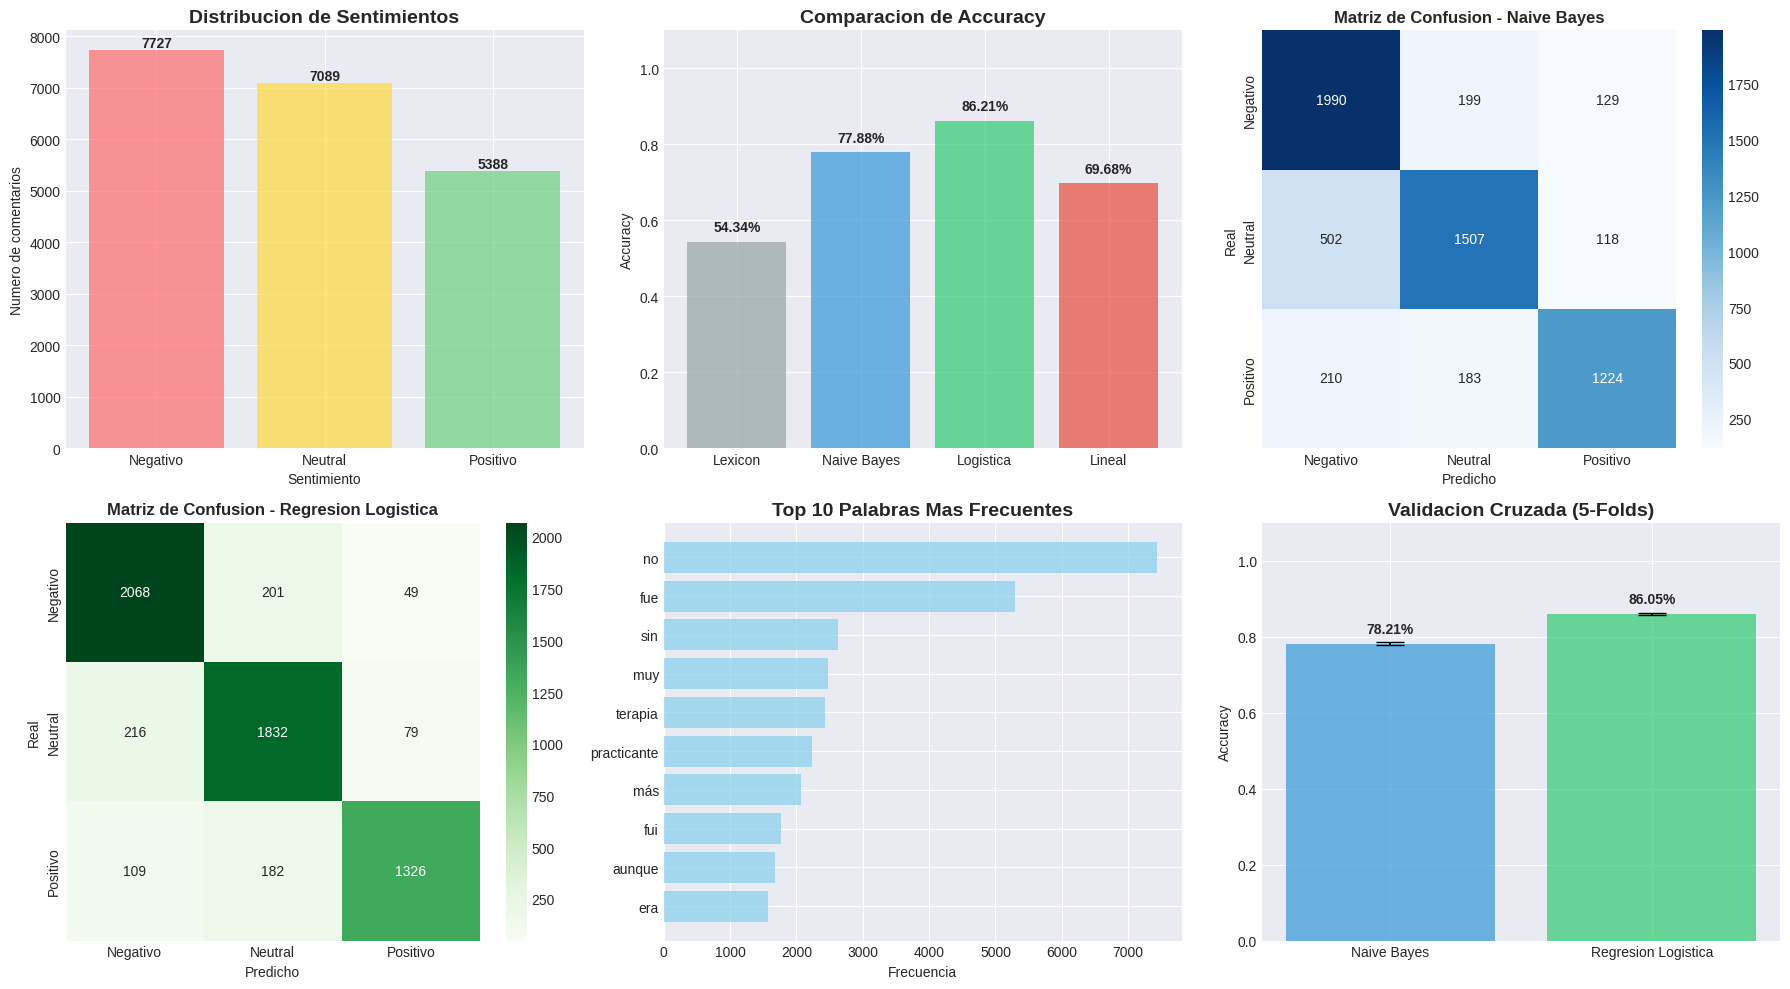


RESUMEN FINAL DEL PROYECTO

 TOTAL DE COMENTARIOS ANALIZADOS: 20204
   Originales: 15705
   YouTube: 4499

TOP 10 PALABRAS MAS FRECUENTES:
   1. 'no': 7437 veces
   2. 'fue': 5292 veces
   3. 'sin': 2631 veces
   4. 'muy': 2472 veces
   5. 'terapia': 2430 veces
   6. 'practicante': 2239 veces
   7. 'más': 2072 veces
   8. 'fui': 1760 veces
   9. 'aunque': 1682 veces
   10. 'era': 1573 veces

COMPARACION DE ACCURACY:
   Metodo Lexicon (Diccionario): 54.34%
   Naive Bayes: 77.88%
   Regresion Logistica: 86.21%
   Regresion Lineal: 69.68%

MEJOR MODELO:
    Regresion Logistica con 86.21% de precision

PROYECTO COMPLETADO EXITOSAMENTE


In [17]:
# =================================================================
# PROYECTO: ANALISIS DE SENTIMIENTOS SOBRE PSEUDOCIENCIAS
# =================================================================

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Configuracion para graficas
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# =================================================================
# 1. CARGA DEL DATASET ORIGINAL Y COMENTARIOS DE YOUTUBE
# =================================================================

def cargar_datos_originales(path):
    """
    Carga el dataset original desde un archivo CSV.
    Si no existe, genera datos de ejemplo.
    """
    try:
        df = pd.read_csv(path)
        print(f" Dataset original '{path}' cargado con exito.")
        print(f"   Dimensiones: {df.shape}")
        return df
    except FileNotFoundError:
        print(" Archivo original no encontrado. Generando dataset de prueba...")
        # Dataset de ejemplo
        comentarios = [
            "La ozonoterapia me curó completamente, excelente tratamiento",
            "El diseno humano es una pseudociencia peligrosa",
            "La moxibustion parece interesante pero no estoy seguro"
        ]
        sentimientos = ['Positivo', 'Negativo', 'Neutral']
        df = pd.DataFrame({'Comentario': comentarios, 'Sentimiento': sentimientos})
        print(f"   Dataset generado con {len(df)} ejemplos")
        return df
    except pd.errors.ParserError as e:
        print(f" Error de parsing al cargar '{path}' con delimitador por defecto: {e}")
        print(" Intentando cargar con delimitador ';'")
        try:
            df = pd.read_csv(path, sep=';') # Try with semicolon delimiter
            print(f" Dataset original '{path}' cargado con exito (usando ';').")
            print(f"   Dimensiones: {df.shape}")
            return df
        except Exception as inner_e:
            print(f" Fallo al cargar '{path}' incluso con delimitador ';': {inner_e}")
            print(f" Continuando con dataset de prueba.")
            # Fallback to example data if semicolon also fails
            comentarios = [
                "La ozonoterapia me curó completamente, excelente tratamiento",
                "El diseno humano es una pseudociencia peligrosa",
                "La moxibustion parece interesante pero no estoy seguro"
            ]
            sentimientos = ['Positivo', 'Negativo', 'Neutral']
            df = pd.DataFrame({'Comentario': comentarios, 'Sentimiento': sentimientos})
            print(f"   Dataset generado con {len(df)} ejemplos")
            return df

def cargar_comentarios_youtube(path):
    """
    Carga los comentarios de YouTube ya limpiados.
    """
    try:
        df = pd.read_csv(path) # Try with default comma delimiter
        print(f" Comentarios de YouTube '{path}' cargados con exito.")
        print(f"   Dimensiones: {df.shape}")
        return df
    except FileNotFoundError:
        print(f" Archivo '{path}' no encontrado. Continuando sin comentarios de YouTube.")
        return pd.DataFrame()
    except pd.errors.ParserError as e:
        print(f" Error de parsing al cargar '{path}' con delimitador por defecto: {e}")
        print(" Intentando cargar con delimitador ';'")
        try:
            df = pd.read_csv(path, sep=';') # Try with semicolon delimiter
            print(f" Comentarios de YouTube '{path}' cargados con exito (usando ';').")
            print(f"   Dimensiones: {df.shape}")
            return df
        except Exception as inner_e:
            print(f" Fallo al cargar '{path}' incluso con delimitador ';': {inner_e}")
            print(f" Continuando sin comentarios de YouTube o revisa el formato del archivo.")
            return pd.DataFrame()

# =================================================================
# 2. LIMPIEZA DE TEXTOS
# =================================================================

def limpiar_texto(texto):
    """
    Limpia el texto eliminando caracteres especiales y normalizando.
    """
    if not isinstance(texto, str):
        return ""

    texto = texto.lower()
    # Abreviaciones comunes
    texto = re.sub(r'\bq\b', 'que', texto)
    texto = re.sub(r'\bx\b', 'por', texto)
    texto = re.sub(r'\btmb\b', 'tambien', texto)
    texto = re.sub(r'\bxd\b', '', texto)
    texto = re.sub(r'\bjaja\b', '', texto)
    texto = re.sub(r'\bjeje\b', '', texto)

    # Eliminar links y menciones
    texto = re.sub(r'http\S+|www\S+|@\w+', '', texto)

    # Limpieza de caracteres (manteniendo la ñ y acentos)
    texto = re.sub(r'[^a-záéíóúñü\s]', ' ', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()

    # Eliminar comentarios muy cortos
    if len(texto) < 5:
        return ""

    return texto

# =================================================================
# 3. DICCIONARIOS PARA METODO LEXICON
# =================================================================

palabras_positivas = {
    'bueno', 'excelente', 'beneficio', 'mejor', 'funciona', 'cura', 'sana',
    'alivio', 'recomendable', 'maravilloso', 'increible', 'efectivo', 'positivo',
    'ayudo', 'cambio', 'profesional', 'energia', 'recuperacion', 'resultado',
    'gracias', 'felicitaciones', 'encanta', 'gusto', 'maravilla', 'recomiendo',
    'agradezco', 'contento', 'feliz', 'genial', 'perfecto', 'exito'
}

palabras_negativas = {
    'malo', 'fraude', 'engano', 'peligro', 'falso', 'ineficaz', 'estafa',
    'dano', 'peor', 'mentira', 'peligrosa', 'sin sentido', 'no sirve',
    'controversial', 'sin evidencia', 'sin base', 'enganosa', 'basura',
    'horrible', 'pesimo', 'decepcion', 'robo', 'chantaje', 'mentiroso'
}

def clasificar_lexicon(texto):
    """
    Clasifica usando un enfoque de diccionario.
    """
    if not isinstance(texto, str) or len(texto) < 5:
        return "Neutral"

    palabras = set(texto.split())
    score = 0

    for palabra in palabras:
        if palabra in palabras_positivas:
            score += 1
        elif palabra in palabras_negativas:
            score -= 1

    if score > 0:
        return "Positivo"
    elif score < 0:
        return "Negativo"
    else:
        return "Neutral"

# =================================================================
# 4. FUNCION PRINCIPAL DE CARGA Y COMBINACION
# =================================================================

def cargar_y_combinar_datos(ruta_original="dataset.csv", ruta_youtube="comentarios_youtube_limpios.csv"):
    """
    Carga y combina los datasets originales y de YouTube.
    Los comentarios de YouTube se etiquetan con el método Lexicon.
    """
    # Cargar datos originales
    df_original = cargar_datos_originales(ruta_original)

    # Limpiar textos originales
    df_original['Comentario_Limpio'] = df_original['Comentario'].apply(limpiar_texto)
    df_original = df_original[df_original['Comentario_Limpio'] != ""]

    # Crear columna Fuente
    df_original['Fuente'] = 'Original'

    print(f"\n Dataset original después de limpieza: {len(df_original)} comentarios")

    # Cargar comentarios de YouTube
    df_youtube = cargar_comentarios_youtube(ruta_youtube)

    if len(df_youtube) > 0:
        # Asegurar que la columna se llame 'Comentario'
        if 'Comentario_Limpio' not in df_youtube.columns and 'Comentario' in df_youtube.columns:
            df_youtube['Comentario_Limpio'] = df_youtube['Comentario']

        # Limpiar textos de YouTube
        df_youtube['Comentario_Limpio'] = df_youtube['Comentario_Limpio'].apply(limpiar_texto)
        df_youtube = df_youtube[df_youtube['Comentario_Limpio'] != ""]

        # Eliminar duplicados
        df_youtube = df_youtube.drop_duplicates(subset=['Comentario_Limpio'])

        # ETIQUETAR con método Lexicon
        df_youtube['Sentimiento'] = df_youtube['Comentario_Limpio'].apply(clasificar_lexicon)
        df_youtube['Fuente'] = 'YouTube'

        print(f" Comentarios YouTube después de limpieza: {len(df_youtube)} comentarios")
        print(f"   Distribución de sentimientos (Lexicon):")
        print(f"   Positivo: {(df_youtube['Sentimiento'] == 'Positivo').sum()}")
        print(f"   Negativo: {(df_youtube['Sentimiento'] == 'Negativo').sum()}")
        print(f"   Neutral: {(df_youtube['Sentimiento'] == 'Neutral').sum()}")

        # COMBINAR DATASETS
        df_combinado = pd.concat([df_original, df_youtube], ignore_index=True)

        print(f"\n DATASET COMBINADO FINAL: {len(df_combinado)} comentarios")
        print(f"   Originales: {len(df_original)}")
        print(f"   YouTube: {len(df_youtube)}")

        return df_combinado
    else:
        print("\n No se encontraron comentarios de YouTube. Usando solo dataset original.")
        return df_original

# =================================================================
# 5. CARGAR Y PREPARAR DATOS
# =================================================================

print("="*60)
print("CARGANDO DATASETS")
print("="*60)

# Cargar y combinar datos
df = cargar_y_combinar_datos("dataset.csv", "comentarios_youtube_limpios.csv")

print("\nPrimeras filas del dataset combinado:")
print(df[['Comentario_Limpio', 'Sentimiento', 'Fuente']].head(10))

# Verificar que tenemos datos
if len(df) == 0:
    print(" No hay datos para procesar. Verifica los archivos.")
    exit()

# =================================================================
# 6. VECTORIZACION (Bag of Words)
# =================================================================

print("\n" + "="*60)
print("VECTORIZACION")
print("="*60)

# Stop words en español
stop_words_espanol = [
    'la', 'el', 'un', 'una', 'de', 'es', 'con', 'me', 'en', 'lo', 'que',
    'se', 'mi', 'su', 'del', 'las', 'los', 'y', 'a', 'al', 'le', 'nos',
    'para', 'por', 'como', 'mas', 'pero', 'esta', 'este', 'esta', 'estoy',
    'yo', 'tu', 'el', 'ella', 'nosotros', 'vosotros', 'ellos', 'este', 'esa'
]

vectorizer = CountVectorizer(
    stop_words=stop_words_espanol,
    max_features=150,  # Aumentado para mejor captura de información
    min_df=2,
    max_df=0.95
)

X = vectorizer.fit_transform(df['Comentario_Limpio'])

# Codificar etiquetas
label_mapping = {'Negativo': 0, 'Neutral': 1, 'Positivo': 2}
y = df['Sentimiento'].map(label_mapping)

print(f"Matriz de caracteristicas: {X.shape}")
print(f"Distribución de sentimientos en dataset combinado:")
print(df['Sentimiento'].value_counts())

# =================================================================
# 7. DIVISION DE DATOS
# =================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"\nDivision de datos:")
print(f"   Entrenamiento: {X_train.shape[0]} muestras")
print(f"   Prueba: {X_test.shape[0]} muestras")

# =================================================================
# 8. MODELOS DE MACHINE LEARNING
# =================================================================

# 8.1 NAIVE BAYES
print("\nEntrenando Naive Bayes...")
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train, y_train)

# 8.2 REGRESION LOGISTICA
print("Entrenando Regresion Logistica...")
lr_model = LogisticRegression(max_iter=1000, random_state=42, C=1.0)
lr_model.fit(X_train, y_train)

# 8.3 REGRESION LINEAL
print("Entrenando Regresion Lineal...")
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_dense)
X_test_scaled = scaler.transform(X_test_dense)

lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)

# =================================================================
# 9. METODO LEXICON (para comparación)
# =================================================================

df['Sentimiento_Lexicon'] = df['Comentario_Limpio'].apply(clasificar_lexicon)
y_pred_lexicon = df['Sentimiento_Lexicon'].map(label_mapping)
acc_lex = accuracy_score(y, y_pred_lexicon)
print(f"\nPrecision del metodo Lexicon en todo el dataset: {acc_lex:.2%}")

# =================================================================
# 10. EVALUACION DE MODELOS
# =================================================================

def evaluar_modelo(nombre, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    print(f"\n{'='*50}")
    print(f"MODELO: {nombre}")
    print(f"{'='*50}")
    print(f"Accuracy: {accuracy:.2%}")
    print(f"\nClassification Report:")
    print(classification_report(y_true, y_pred,
                                target_names=['Negativo', 'Neutral', 'Positivo'],
                                zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    return accuracy, cm

# Predicciones
y_pred_nb = nb_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)
y_pred_lin = np.clip(np.round(lin_model.predict(X_test_scaled)), 0, 2).astype(int)

# Evaluar
acc_nb, cm_nb = evaluar_modelo("Naive Bayes", y_test, y_pred_nb)
acc_lr, cm_lr = evaluar_modelo("Regresion Logistica", y_test, y_pred_lr)
acc_lin, cm_lin = evaluar_modelo("Regresion Lineal", y_test, y_pred_lin)

# Validacion cruzada
print(f"\n{'='*50}")
print("VALIDACION CRUZADA (5 folds)")
print(f"{'='*50}")
cv_nb = cross_val_score(nb_model, X_train, y_train, cv=5, scoring='accuracy')
cv_lr = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='accuracy')
print(f"Naive Bayes - CV Accuracy: {cv_nb.mean():.2%} (+/- {cv_nb.std()*2:.2%})")
print(f"Regresion Logistica - CV Accuracy: {cv_lr.mean():.2%} (+/- {cv_lr.std()*2:.2%})")

# =================================================================
# 11. VISUALIZACIONES
# =================================================================

fig = plt.figure(figsize=(18, 10))

# 11.1 Distribucion de sentimientos
ax1 = plt.subplot(2, 3, 1)
sentiment_counts = df['Sentimiento'].value_counts()
colors = ['#ff6b6b', '#ffd93d', '#6bcf7f']
bars = ax1.bar(sentiment_counts.index, sentiment_counts.values, color=colors, alpha=0.7)
ax1.set_title('Distribucion de Sentimientos', fontsize=14, fontweight='bold')
ax1.set_ylabel('Numero de comentarios')
ax1.set_xlabel('Sentimiento')
for bar, count in zip(bars, sentiment_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             str(count), ha='center', va='bottom', fontweight='bold')

# 11.2 Comparacion de Accuracy
ax2 = plt.subplot(2, 3, 2)
modelos = ['Lexicon', 'Naive Bayes', 'Logistica', 'Lineal']
scores = [acc_lex, acc_nb, acc_lr, acc_lin]
colors_bar = ['#95a5a6', '#3498db', '#2ecc71', '#e74c3c']
bars = ax2.bar(modelos, scores, color=colors_bar, alpha=0.7)
ax2.set_title('Comparacion de Accuracy', fontsize=14, fontweight='bold')
ax2.set_ylabel('Accuracy')
ax2.set_ylim([0, 1.1])
for bar, score in zip(bars, scores):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{score:.2%}', ha='center', va='bottom', fontweight='bold')

# 11.3 Matriz confusion - Naive Bayes
ax3 = plt.subplot(2, 3, 3)
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues', ax=ax3,
            xticklabels=['Negativo', 'Neutral', 'Positivo'],
            yticklabels=['Negativo', 'Neutral', 'Positivo'])
ax3.set_title('Matriz de Confusion - Naive Bayes', fontsize=12, fontweight='bold')
ax3.set_ylabel('Real')
ax3.set_xlabel('Predicho')

# 11.4 Matriz confusion - Regresion Logistica
ax4 = plt.subplot(2, 3, 4)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Greens', ax=ax4,
            xticklabels=['Negativo', 'Neutral', 'Positivo'],
            yticklabels=['Negativo', 'Neutral', 'Positivo'])
ax4.set_title('Matriz de Confusion - Regresion Logistica', fontsize=12, fontweight='bold')
ax4.set_ylabel('Real')
ax4.set_xlabel('Predicho')

# 11.5 Top palabras frecuentes
ax5 = plt.subplot(2, 3, 5)
sum_words = X.sum(axis=0).A1
words_freq = [(word, idx) for word, idx in vectorizer.vocabulary_.items()]
# Ensure words_freq is sorted by actual frequency after getting sums
words_freq_with_sums = []
for word, idx in vectorizer.vocabulary_.items():
    words_freq_with_sums.append((word, sum_words[idx]))
words_freq = sorted(words_freq_with_sums, key=lambda x: x[1], reverse=True)[:10]
palabras, frecuencias = zip(*words_freq)

bars = ax5.barh(palabras, frecuencias, color='skyblue', alpha=0.7)
ax5.set_title('Top 10 Palabras Mas Frecuentes', fontsize=14, fontweight='bold')
ax5.set_xlabel('Frecuencia')
ax5.invert_yaxis()

# 11.6 Validacion cruzada
ax6 = plt.subplot(2, 3, 6)
cv_data = [cv_nb.mean(), cv_lr.mean()]
cv_std = [cv_nb.std(), cv_lr.std()]
x_pos = np.arange(len(['Naive Bayes', 'Logistica']))
bars = ax6.bar(x_pos, cv_data, yerr=cv_std, capsize=10, color=['#3498db', '#2ecc71'], alpha=0.7)
ax6.set_title('Validacion Cruzada (5-Folds)', fontsize=14, fontweight='bold')
ax6.set_ylabel('Accuracy')
ax6.set_xticks(x_pos)
ax6.set_xticklabels(['Naive Bayes', 'Regresion Logistica'])
ax6.set_ylim([0, 1.1])
for bar, score in zip(bars, cv_data):
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{score:.2%}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# =================================================================
# 12. RESULTADOS FINALES
# =================================================================

print("\n" + "="*60)
print("RESUMEN FINAL DEL PROYECTO")
print("="*60)

print(f"\n TOTAL DE COMENTARIOS ANALIZADOS: {len(df)}")
print(f"   Originales: {(df['Fuente'] == 'Original').sum()}")
print(f"   YouTube: {(df['Fuente'] == 'YouTube').sum()}")

print("\nTOP 10 PALABRAS MAS FRECUENTES:")
for i, (word, freq) in enumerate(words_freq[:10], 1):
    print(f"   {i}. '{word}': {freq} veces")

print("\nCOMPARACION DE ACCURACY:")
print(f"   Metodo Lexicon (Diccionario): {acc_lex:.2%}")
print(f"   Naive Bayes: {acc_nb:.2%}")
print(f"   Regresion Logistica: {acc_lr:.2%}")
print(f"   Regresion Lineal: {acc_lin:.2%}")

print("\nMEJOR MODELO:")
best_model_idx = np.argmax([acc_lex, acc_nb, acc_lr, acc_lin])
best_model_name = ['Lexicon', 'Naive Bayes', 'Regresion Logistica', 'Regresion Lineal'][best_model_idx]
best_score = max([acc_lex, acc_nb, acc_lr, acc_lin])
print(f"    {best_model_name} con {best_score:.2%} de precision")

print("\n" + "="*60)
print("PROYECTO COMPLETADO EXITOSAMENTE")
print("="*60)
